In [1]:
%%capture
import sys
!{sys.executable} -m pip install pandas --no-index
!{sys.executable} -m pip install matplotlib --no-index
!{sys.executable} -m pip install seaborn --no-index

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### Import Study Data

In [3]:
output_path = ''

def read_file(file):
    file_path = os.path.join(output_path, file)
    csv = pd.read_csv(file_path, sep='\t')
    return csv

In [4]:
gp = '' #ouput dirtory of Random Forest Ancestry Predictor 
proPC = read_file(f'{gp}/trace.ProPC.coord')

FileNotFoundError: [Errno 2] No such file or directory: '/trace.ProPC.coord'

In [ ]:
# Exploration of ancestry inference result 
predict = read_file(f'{gp}/predicted_ancestry.txt')
predict.predicted_ancestry.value_counts()

data = pd.merge(proPC, predict, on='indivID')
data.groupby('predicted_ancestry').max_prob.describe()

predicted_ancestry
EUR    100
AMR      3
Name: count, dtype: int64

### Establish an ancestry prediction threshold

In [ ]:
undef_label = "UND"

def anc_cutoff(col_title, prob_cutoff):
    data[col_title] = np.where((data.max_prob < prob_cutoff), 
                               undef_label,
                               data.predicted_ancestry)
    
anc_cutoff('ancestry_07', 0.7) 
data.groupby('ancestry_07').max_prob.describe()

## import reference data

In [ ]:
refPC = read_file(f'{gp}/reference.RefPC.coord')
ref_labels = pd.read_csv('path/to/HGDP_1KG/metadata.csv')
ref_data = pd.merge(refPC.drop(columns='popID'), ref_labels, left_on='indivID', right_on='ID', how='left')

renamed_label = 'population'
pd.DataFrame(ref_labels.rename(columns={"genetic_region": renamed_label})[renamed_label].value_counts()).reset_index()

# global plots
## plot reference data

In [26]:
save_yes = True
save_dir = f'{gp}'+"/plot/"

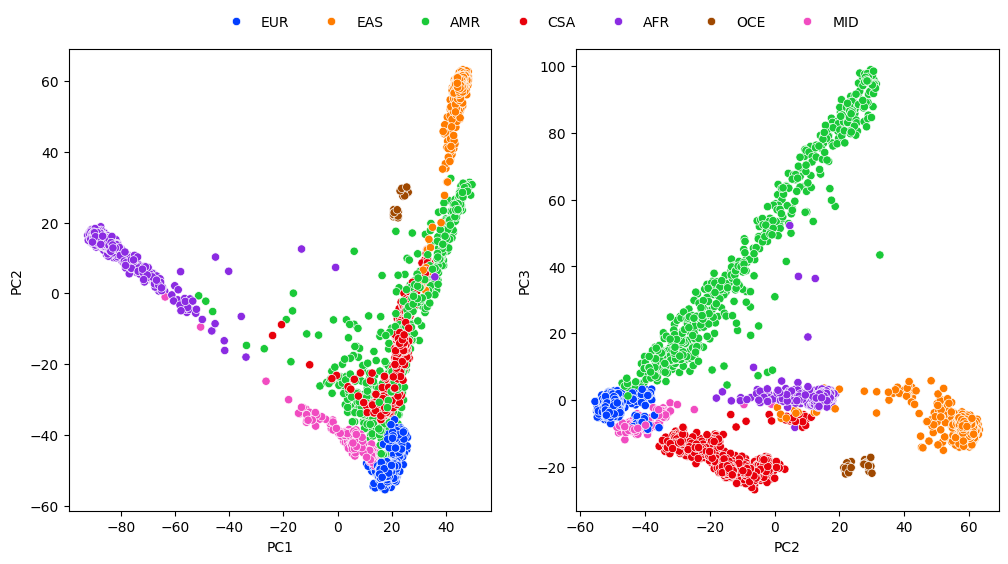

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(12,6))

palt = 'bright'
alph = 1

to_plot = [ ['PC1', 'PC2'], ['PC2', 'PC3'] ]
pcs_x, pcs_y = to_plot[0][0], to_plot[0][1]
sns.scatterplot(ax=ax[0], x=pcs_x, y=pcs_y, data=ref_data, hue='genetic_region', palette=palt, alpha=alph, legend=False)

pcs_x, pcs_y = to_plot[1][0], to_plot[1][1]
sns.scatterplot(ax=ax[1], x=pcs_x, y=pcs_y, data=ref_data, hue='genetic_region', palette=palt, alpha=alph)
ax[1].legend(bbox_to_anchor=[0.7,1.1], ncol=7, frameon=False)

fig.savefig(f'{save_dir}/PC_HGDP_1KG_only.png', dpi=500, bbox_inches='tight')

In [29]:
ref_data.genetic_region.value_counts()

genetic_region
AFR    994
EAS    821
CSA    788
EUR    776
AMR    549
MID    161
OCE     30
Name: count, dtype: int64

## Plot study data projected on reference [global]


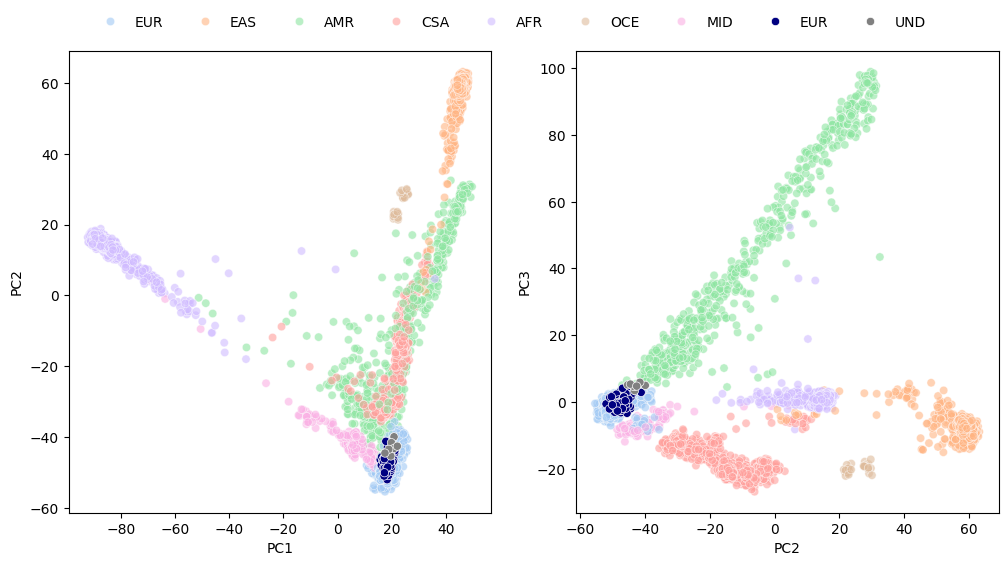

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(12,6))

to_plot = [ ['PC1', 'PC2'], ['PC2', 'PC3'] ]
lt=True
for i in [0, 1]:
    pcs_x, pcs_y = to_plot[i][0], to_plot[i][1]
    sns.scatterplot(ax=ax[i], x=pcs_x, y=pcs_y, data=ref_data, hue='genetic_region', palette='pastel', alpha=0.6, legend=lt)
    pal_d = {'EUR': 'navy', undef_label:'grey'}
    ancestry_col = 'ancestry_07'
    for a in ['EUR', undef_label]:
        sns.scatterplot(ax=ax[i], x=pcs_x, y=pcs_y, data=data[data[ancestry_col]==a], hue=ancestry_col, palette=[pal_d[a]], legend=lt)
    ax[i].get_legend().remove()

# add legend
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=[0.85,0.96], ncol=9, frameon=False)

if save_yes == True:
    fig.savefig(f'{save_dir}/PCs_global_ref.png', dpi=500, bbox_inches='tight')

In [31]:
from matplotlib.patches import ConnectionPatch

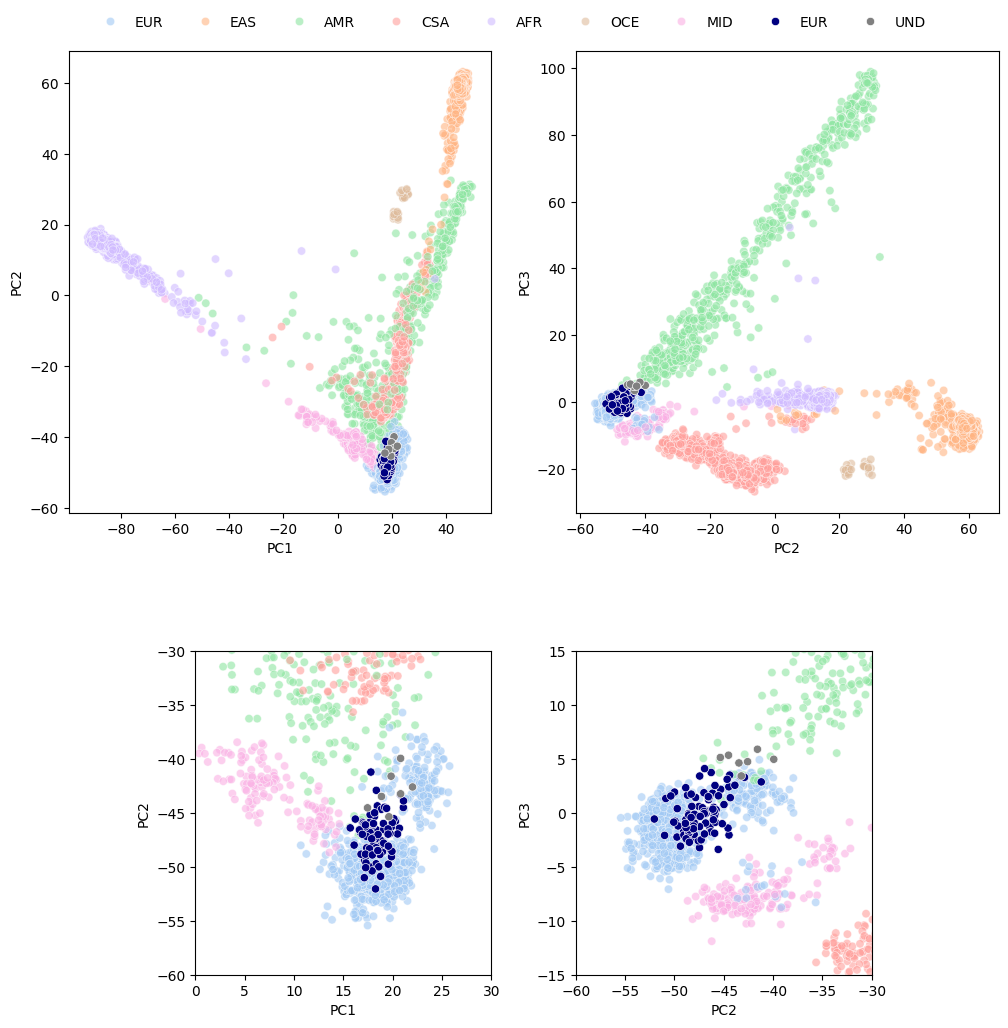

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(12,6))#, sharey=True)

to_plot = [ ['PC1', 'PC2'], ['PC2', 'PC3'] ]
lt=True

for i in [0, 1]:
    pcs_x, pcs_y = to_plot[i][0], to_plot[i][1]
    sns.scatterplot(ax=ax[i], x=pcs_x, y=pcs_y, data=ref_data, hue='genetic_region', palette='pastel', alpha=0.6, legend=lt)
    
    if i == 0:
        axin = ax[i].inset_axes([0.3, -1, 0.7, 0.7])
        axin.set(xlim=(0,30),ylim=(-60,-30))
    else:
        axin = ax[i].inset_axes([0, -1, 0.7, 0.7])
        axin.set(xlim=(-60,-30),ylim=(-15,15))

    sns.scatterplot(ax=axin, x=pcs_x, y=pcs_y, data=ref_data, hue='genetic_region', palette='pastel', alpha=0.6, legend=None)
    
    
    pal_d = {'EUR': 'navy', undef_label:'grey'}

    ancestry_col = 'ancestry_07'
    for a in ['EUR', undef_label]:
        sns.scatterplot(ax=ax[i], x=pcs_x, y=pcs_y, data=data[data[ancestry_col]==a], hue=ancestry_col, palette=[pal_d[a]], legend=lt)
        sns.scatterplot(ax=axin, x=pcs_x, y=pcs_y, data=data[data[ancestry_col]==a], hue=ancestry_col, palette=[pal_d[a]], legend=None)

    ax[i].get_legend().remove()
    

# add legend
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=[0.85,0.96], ncol=9, frameon=False)

if save_yes == True:
    fig.savefig(f'{save_dir}/PCs_global_ref-proj_zoom.png', dpi=500, bbox_inches='tight')

# EUR specific analysis
## subset to EUR reference + import eur population labels

In [ ]:
updated_labels = ref_labels.merge(read_file('hgdp_tgp_meta.tsv')[['s', 'hgdp_tgp_meta.Population']], left_on='ID', right_on='s', how='left').drop(columns=['s'])
EUR_populations = updated_labels[updated_labels['genetic_region'] == 'EUR'][['ID', 'hgdp_tgp_meta.Population']]

ref_data['population'] = updated_labels['hgdp_tgp_meta.Population']

In [ ]:
eo = '' #Output for infrence with european subset 
EUR_refPC = read_file(f'{eo}/reference.RefPC.coord')
EUR_ref_labels = pd.read_csv(f'{eo}/EUR_populations.csv')
EURref = pd.merge(EUR_refPC.drop(columns='popID'), EUR_ref_labels, left_on='indivID', right_on='ID', how='left').rename(columns = {'genetic_region':'population'})
EURref['label_origin'] = np.where(EURref.population.str.len() == 3, '1KG', 'HGDP')

## Plot study data projected on reference [EUR subset of HGDP_1KG]

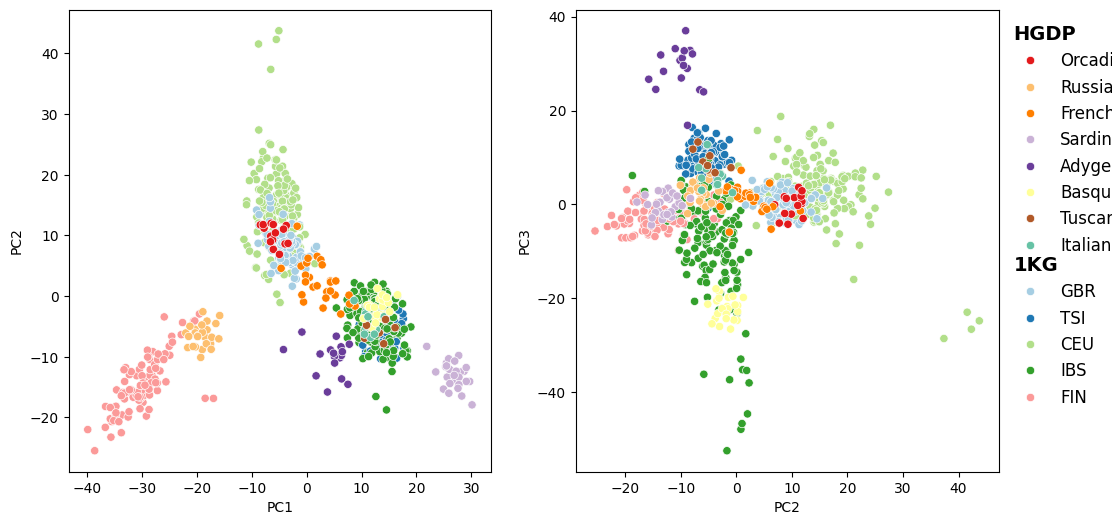

In [66]:
fig, ax = plt.subplots(1,2, figsize=(12,6))#, sharey=True)
# fig, ax = plt.subplots(1, 2, figsize=(10,6), gridspec_kw={'width_ratios': [2, 1]})

# palt = sns.color_palette("hls", 13)
palt = sns.color_palette("Paired")+[sns.color_palette("Set2")[0]]
alph = 1
dat = EURref.sort_values(by='label_origin') #EURref.sort_values(by='population')

to_plot = [ ['PC1', 'PC2'], ['PC2', 'PC3'] ]
pcs_x, pcs_y = to_plot[0][0], to_plot[0][1]
sns.scatterplot(ax=ax[0], x=pcs_x, y=pcs_y, data=dat, hue='population', palette=palt, alpha=alph, legend=False)

pcs_x, pcs_y = to_plot[1][0], to_plot[1][1]
sns.scatterplot(ax=ax[1], x=pcs_x, y=pcs_y, data=dat, hue='population', palette=palt, alpha=alph)
# ax[1].legend(bbox_to_anchor=[1.05,1], ncol=1, frameon=False)

handles, labels = ax[1].get_legend_handles_labels()
vals = EURref.groupby("label_origin").nunique().population['1KG']
KG_handles, KG_labels = handles[:vals], labels[:vals]
HGDP_handles, HGDP_labels = handles[vals:], labels[vals:]

def insert_legend(title, handles, labels, height):
    legend_x = ax[1].legend(handles, labels, title=title, frameon=False, alignment="left",
                           loc="upper left", bbox_to_anchor=(1, height), fontsize=12
                           )
    plt.setp(legend_x.get_title(), fontweight='bold', fontsize=14)  
    # sns.move_legend(ax[1], "upper left", bbox_to_anchor=(1, height))
    return legend_x

# legend = insert_legend("", HGDP_handles + KG_handles, HGDP_labels + KG_labels, 1)
legend_a = insert_legend("HGDP", HGDP_handles, HGDP_labels, 1)
legend_b = insert_legend("1KG", KG_handles, KG_labels, 0.5)

ax[1].add_artist(legend_a)
# legend_a.set_bbox_to_anchor((1, 1))
# legend_b.set_bbox_to_anchor((1, 0.5))

# # ax[1].set(xlim=(0,150),ylim=(-200,100))

if save_yes == True:
    fig.savefig(f'{save_dir}/PCs_EUR_ref-only.png', dpi=500, bbox_extra_artists=(legend_a,legend_b), bbox_inches='tight')

### Import EUR-sp projected study data

In [7]:
EUR_proPC = read_file(f'{eo}/trace.ProPC.coord')
# sns.boxplot(EUR_proPC.Z)
# EUR_proPC.Z.describe()

EUR_predict = read_file(f'{eo}/predicted_ancestry.txt')
# EUR_predict.predicted_ancestry.value_counts()

EUR_out = pd.merge(EUR_proPC, EUR_predict, on='indivID')

EUR_out = EUR_out.rename(columns={'predicted_ancestry':'predicted_population'})
# EUR_out.predicted_population
EUR_out = pd.merge(EUR_out, data[['indivID','predicted_ancestry']], on='indivID').rename(columns={'predicted_ancestry':'global_ancestry_prediction'}) 

# EUR_out
# sns.boxplot(EUR_out.max_prob)

NameError: name 'eo' is not defined

In [ ]:
thr = 0.5
thr_quer = EUR_predict.max_prob > thr
print( len( EUR_predict[thr_quer] ))

26


### Calculate EUR-sp population prediction thresholds

In [ ]:
def eur_cutoff(col_title, prob_cutoff):
    EUR_out[col_title] = np.where((EUR_out.max_prob < prob_cutoff), 
                               'undefined',
                               EUR_out.predicted_population)
    
for i in range(0,10):
    thr = i/10
    eur_cutoff(f'population_{thr}', thr)

## Add gloabal ancestry label
EUR_out["global_ancestry_07"] = data["ancestry_07"]

In [ ]:
cols = [col for col in EUR_out if col.startswith('population_')]

eur_counts = pd.DataFrame()
for i in range(0,10):
    c = f'population_{i/10}'
    eur_counts[f'{i/10}'] = EUR_out[c].value_counts()
    
eur_counts = eur_counts.fillna('0')
eur_counts.index.name = None
eur_counts

,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
French,60,60,60,57.0,39.0,21.0,9.0,0,0,0
GBR,35,35,35,34.0,20.0,4.0,1.0,0,0,0
CEU,5,5,5,5.0,2.0,1.0,0,0,0,0
IBS,1,1,1,0,0,0,0,0,0,0
FIN,1,1,1,0,0,0,0,0,0,0
TSI,1,1,1,1.0,1.0,1.0,1.0,1.0,0,0


## plot projected study data on reference [EUR]

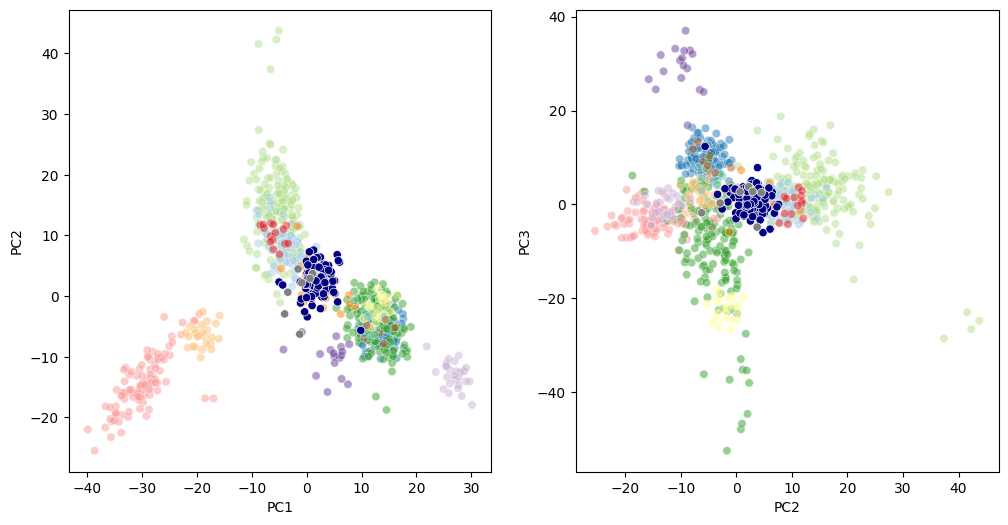

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(12,6))

EUR_out['study'] = 'Study'
EUR_out['pop_label'] = EUR_out['global_ancestry_07']

palt = sns.color_palette("Paired")+[sns.color_palette("Set2")[0]]
alph = 0.5

to_plot = [ ['PC1', 'PC2'], ['PC2', 'PC3'] ]
lt=True

for i in [0, 1]:
    pcs_x, pcs_y = to_plot[i][0], to_plot[i][1]

    ## plot ref
    dat = EURref.sort_values(by='label_origin')
    sns.scatterplot(ax=ax[i], x=pcs_x, y=pcs_y, data=dat, hue='population', palette=palt, alpha=alph, legend=lt)
    
    ## plot study
    pal_d = {'UND':'grey', 'EUR': 'navy'}
    ancestry_col = 'global_ancestry_07'
    for a in ['EUR', 'UND']:
        sns.scatterplot(ax=ax[i], x=pcs_x, y=pcs_y, data=EUR_out[EUR_out[ancestry_col]==a], hue=ancestry_col, palette=[pal_d[a]], legend=lt)

    ax[i].get_legend().remove()

# add legend
handles, labels = ax[1].get_legend_handles_labels()
KG_handles, KG_labels = handles[0:5], labels[0:5]
HGDP_handles, HGDP_labels = handles[5:13], labels[5:13]
Study_handles, Study_labels = handles[13:15], labels[13:15]

legend_a = insert_legend("HGDP", HGDP_handles, HGDP_labels, 1)
legend_b = insert_legend("1KG", KG_handles, KG_labels, 0.6)
legend_c = insert_legend("Study", Study_handles, Study_labels, 1)

ax[1].add_artist(legend_c)

if save_yes == True:
    fig.savefig(f'{save_dir}/PCs_EUR_ref_proj_a05.png', bbox_extra_artists=(legend_a,legend_b), dpi=500, bbox_inches='tight')